# TensorFlow 常用 API

用几组小数组说明常用 API 怎么用：先看输入和输出，再看模型怎样训练。代码按顺序运行，内核选项目的 `.venv`。


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
from keras import Sequential, Input
from keras.layers import Dense, Normalization
from keras.losses import MeanSquaredError, BinaryCrossentropy, SparseCategoricalCrossentropy
from keras.optimizers import Adam

# 固定随机种子，让每次运行的结果尽量一致。
keras.utils.set_random_seed(2)
np.set_printoptions(precision=3, suppress=True)
print("TensorFlow 版本：", tf.__version__)


TensorFlow 版本： 2.21.0


Keras 提供搭建神经网络的接口，TensorFlow 负责底层计算。`tf.keras.layers.Dense` 与这里导入的 `Dense` 在 TensorFlow 后端下用途相同。

## 1. 数组和张量

Tensor 可以先当成 TensorFlow 的多维数组来看。`shape` 是形状，`dtype` 是元素类型；本例用 `float32` 存小数。

下面的输入按“一行一个样本，一列一个特征”摆放。两个样本，每个样本有两个特征，所以形状是 `(2, 2)`。


In [2]:
X = np.array([[1, 10], [2, 20]], dtype=np.float32)
x_tensor = tf.constant(X)  # 把 NumPy 数组转成 Tensor

print(x_tensor)
print("形状：", x_tensor.shape)
print("转回 NumPy：\n", x_tensor.numpy())

# X[0] 只剩两个特征；X[0:1] 仍保留“一行”的结构。
print("X[0] 的形状：", X[0].shape)       # (2,)
print("X[0:1] 的形状：", X[0:1].shape)   # (1, 2)


tf.Tensor(
[[ 1. 10.]
 [ 2. 20.]], shape=(2, 2), dtype=float32)
形状： (2, 2)
转回 NumPy：
 [[ 1. 10.]
 [ 2. 20.]]
X[0] 的形状： (2,)
X[0:1] 的形状： (1, 2)


预测一个样本时也要保留样本维。`X[i].reshape(1, -1)` 中，`1` 表示一个样本，`-1` 让 NumPy 自动算出有几个特征。

## 2. 一个神经元

`Dense` 是全连接层，`units=1` 表示层里有一个神经元。`activation="linear"` 不改变线性计算的结果，所以这一层算的还是：

$$\hat y=wx+b$$

>  全连接层：这一层的每个神经元，都接收上一层所有神经元的输出。


In [3]:
X_linear = np.array([[1.0], [2.0]], dtype=np.float32)
linear_layer = Dense(units=1, activation="linear")

print("调用前的参数：", linear_layer.get_weights())  # []，尚未创建参数
first_output = linear_layer(X_linear)  # 第一次调用时，层才知道输入有几个特征
W, b = linear_layer.get_weights()
print("初始 W：", W, "初始 b：", b)
print("初始预测：\n", first_output.numpy())


调用前的参数： []
初始 W： [[0.985]] 初始 b： [0.]
初始预测：
 [[0.985]
 [1.97 ]]


此时权重是随机初始化的，还没有训练。`get_weights()` 取出的是 `[W, b]` 两个 NumPy 数组。

手动把权重改成 `2`，偏置改成 `1`，看看 TensorFlow 和 NumPy 的计算是否一致。


In [4]:
linear_layer.set_weights([
    np.array([[2.0]], dtype=np.float32),  # W 的形状：(输入特征数, 神经元数)
    np.array([1.0], dtype=np.float32),    # b 的形状：(神经元数,)
])
W, b = linear_layer.get_weights()
y_tf = linear_layer(X_linear).numpy()
y_np = X_linear @ W + b  # @ 是矩阵乘法
print("TensorFlow：\n", y_tf)
print("NumPy：\n", y_np)


TensorFlow：
 [[3.]
 [5.]]
NumPy：
 [[3.]
 [5.]]


两边都是 `3`、`5`。这是因为我们指定了参数，不是因为模型自己学会了。

如果一层有多个神经元，公式就是 `A = g(X @ W + b)`，其中 `g` 是激活函数。输入有 2 个特征、输出有 4 个神经元时，`W` 的形状为 `(2, 4)`，`b` 的形状为 `(4,)`。

## 3. 把两层接起来

`Sequential` 按列表顺序连接各层。下面用两项特征预测一个二分类标签：隐藏层有 4 个神经元，输出层有 1 个。

数据只用于演示 API。`y_train` 中的 `0`、`1` 表示类别，不是特征。


In [5]:
X_train = np.array([
    [1, 10], [2, 11], [3, 10], [4, 12],
    [7, 13], [8, 14], [9, 13], [10, 15],
], dtype=np.float32)
y_train = np.array([[0], [0], [0], [0], [1], [1], [1], [1]], dtype=np.float32)

# 两列的数值范围不同，先分别做标准化。
norm = Normalization(axis=-1)  # -1 表示最后一维，也就是特征维
norm.adapt(X_train)  # 统计训练集每列的均值和方差，不是在训练神经网络
Xn = norm(X_train)   # 使用这些统计量转换输入
print("标准化后的输入：\n", Xn.numpy())


标准化后的输入：
 [[-1.406 -1.313]
 [-1.093 -0.729]
 [-0.781 -1.313]
 [-0.469 -0.146]
 [ 0.469  0.438]
 [ 0.781  1.021]
 [ 1.093  0.438]
 [ 1.406  1.605]]


标准化后的每列接近零均值、单位方差，并不是缩放到 `[0, 1]`。新数据也用这个 `norm` 转换，不要重新 `adapt`。有验证集或测试集时，也只用训练集统计均值和方差。


In [6]:
model = Sequential([
    Input(shape=(2,)),  # 一个样本有两个特征；这里不写样本数
    Dense(4, activation="relu", name="hidden"),  # ReLU：负数变成 0，正数不变
    Dense(1, activation="sigmoid", name="output"),
])
model.summary()

# 取出指定层，查看参数。也可以用 model.layers[0] 取第一层 Dense。
hidden = model.get_layer("hidden")
W_hidden, b_hidden = hidden.get_weights()
print("隐藏层参数形状：", W_hidden.shape, b_hidden.shape)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ hidden (Dense)                  │ (None, 4)              │            12 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │             5 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 17 (68.00 B)

 Trainable params: 17 (68.00 B)

 Non-trainable params: 0 (0.00 B)

隐藏层参数形状： (2, 4) (4,)


输入经过网络时，形状从 `(m, 2)` 变为 `(m, 4)`，最后是 `(m, 1)`；`m` 是这一批的样本数。`summary()` 中的 `None` 表示样本数没有固定。

隐藏层有 `2×4+4=12` 个参数，输出层有 `4×1+1=5` 个，总计 17 个。`units` 决定输出数，不是输入特征数。

最后的 sigmoid 把每个输出映射到 `(0, 1)`，用来表示属于类别 `1` 的概率。

## 4. 训练和预测

`compile` 配置训练方式，`fit` 才会更新参数。二分类输出已经是概率，所以使用 `BinaryCrossentropy()`；`Adam` 是优化器，负责根据梯度更新权重。


In [ ]:
model.compile(
    optimizer=Adam(learning_rate=0.1), # Adam 是一种利用梯度自动调整参数更新步幅的优化算法
    loss=BinaryCrossentropy(), #  二分类交叉熵损失
    metrics=["accuracy"],  # 额外显示准确率；优化的目标仍然是 loss
)

# evaluate 只计算损失和指标，不更新参数。return_dict=True 让结果带上名字。
before = model.evaluate(Xn, y_train, verbose=0, return_dict=True)
history = model.fit(
    Xn, y_train,
    epochs=40,     # 把整个训练集看 40 遍
    batch_size=8,  # 每批 8 条数据；这个小例子每一遍只更新一次
    verbose=0,     # 不显示进度条；改成 1 可以观察训练过程
)
after = model.evaluate(Xn, y_train, verbose=0, return_dict=True)
print("训练前：", before)
print("训练后：", after)


训练前： {'accuracy': 0.5, 'loss': 0.6017467975616455}
训练后： {'accuracy': 1.0, 'loss': 4.869620897807181e-05}


`epochs` 不是梯度更新次数。一般每遍有多批数据，每一批更新一次参数。

`history.history["loss"]` 保存每一遍的训练损失。下面画的是训练集上的变化，不能单凭这条曲线判断对新数据的预测好不好。


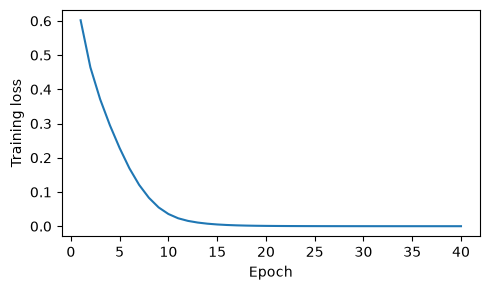

In [8]:
plt.figure(figsize=(5, 3))
plt.plot(np.arange(1, len(history.history["loss"]) + 1), history.history["loss"])
plt.xlabel("Epoch")
plt.ylabel("Training loss")
plt.tight_layout()
plt.show()


In [9]:
X_test = np.array([[1.5, 10], [9.5, 14]], dtype=np.float32)
X_test_n = norm(X_test)  # 与训练时使用同一套标准化

probabilities = model.predict(X_test_n, verbose=0)  # 返回 NumPy 数组
classes = (probabilities >= 0.5).astype(np.int32)   # 把概率变成类别
print("属于类别 1 的概率：\n", probabilities)
print("预测类别：\n", classes)

# 少量数据也可以直接调用模型，结果是 Tensor，不会因此训练模型。
direct_output = model(X_test_n, training=False)
print("直接调用：\n", direct_output.numpy())


属于类别 1 的概率：
 [[0.]
 [1.]]
预测类别：
 [[0]
 [1]]
直接调用：
 [[0.]
 [1.]]


## 5. 多分类与 logits

多分类时，每个样本输出的数值个数等于类别数。下面有三个类别，最后一层用 `Dense(3, activation="linear")`，配 `SparseCategoricalCrossentropy(from_logits=True)`。

这里的三个输出是原始分数，叫 logits，还不是概率。`from_logits=True` 告诉损失函数按原始分数计算；把 softmax 和交叉熵放在一起计算，数值上更稳定。

要查看概率，再调用 `tf.nn.softmax`。如果最后一层已经用了 `softmax`，损失就应该使用默认的 `from_logits=False`。二分类也一样：sigmoid 输出配默认交叉熵，linear 输出才配 `from_logits=True`。

先用三个小点簇演示多分类。`Sparse` 表示标签直接用 `0、1、2` 这样的类别编号，不需要手动改成 one-hot。


In [10]:
X_multi = np.array([
    [-2, -1], [-2, 0], [-1, -2],  # 类别 0
    [2, -1], [2, 0], [2, 1],     # 类别 1
    [0, 2], [-1, 2], [1, 2],     # 类别 2
], dtype=np.float32)
y_multi = np.array([0, 0, 0, 1, 1, 1, 2, 2, 2], dtype=np.int32)

multi_model = Sequential([
    Input(shape=(2,)),
    Dense(8, activation="relu"),  # ReLU 把负数变成 0，正数保持不变
    Dense(3, activation="linear"),
])
multi_model.compile(
    optimizer=Adam(learning_rate=0.05),
    loss=SparseCategoricalCrossentropy(from_logits=True),
)
multi_model.fit(X_multi, y_multi, epochs=30, batch_size=9, verbose=0);


In [11]:
logits = multi_model.predict(X_multi, verbose=0)  # 9 个样本，每行 3 个分数
multi_probabilities = tf.nn.softmax(logits, axis=-1).numpy()
multi_classes = np.argmax(logits, axis=1)  # 每行取最大值的位置，得到类别编号

print("第一个样本的原始分数：", logits[0])
print("对应的三个概率：", multi_probabilities[0])
print("预测类别：", multi_classes)
print("真实类别：", y_multi)

# 对齐为一维后再比较，避免 (m,) 和 (m, 1) 广播成 (m, m)。
error_rate = np.mean(multi_classes != y_multi.reshape(-1))
print("训练集错分率：", error_rate)


第一个样本的原始分数： [ 2.705 -4.877 -5.429]
对应的三个概率： [0.999 0.001 0.   ]
预测类别： [0 0 0 1 1 1 2 2 2]
真实类别： [0 0 0 1 1 1 2 2 2]
训练集错分率： 0.0


`axis=1` 是沿每一行的列方向取最大值。softmax 不改变这一行分数的大小顺序，所以只需要类别时，可以直接对 logits 做 `argmax`。

这里的错分率和交叉熵损失不是一回事。错分率只看预测类别对不对，交叉熵还反映模型给真实类别分配了多少概率。

## 6. 回归任务的损失

如果要预测的是价格、温度这样的数值，而不是类别，输出层通常用 `linear`，损失可以选 `MeanSquaredError()`，也就是均方误差。

损失函数的调用顺序是 `loss(真实值, 预测值)`。下面两次预测的误差分别是 `0`、`1`，平方后取平均得到 `0.5`。


In [12]:
mse = MeanSquaredError()
y_true = tf.constant([[1.0], [2.0]])
y_pred = tf.constant([[1.0], [3.0]])
print("均方误差：", float(mse(y_true, y_pred)))


均方误差： 0.5


这里用训练集展示了 `evaluate` 的返回值。实际评估模型应使用没有参与训练的数据：训练集用来更新参数，验证集帮助选模型，测试集用于最后评估。

有时会在 `Dense` 中看到 `kernel_regularizer=keras.regularizers.l2(0.01)`。它把权重平方和的 `0.01` 倍加入损失，限制权重过大；不会改变输出形状，也不等同于输入标准化。
